In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

data = pd.read_csv("flight_data_cleaned.csv")

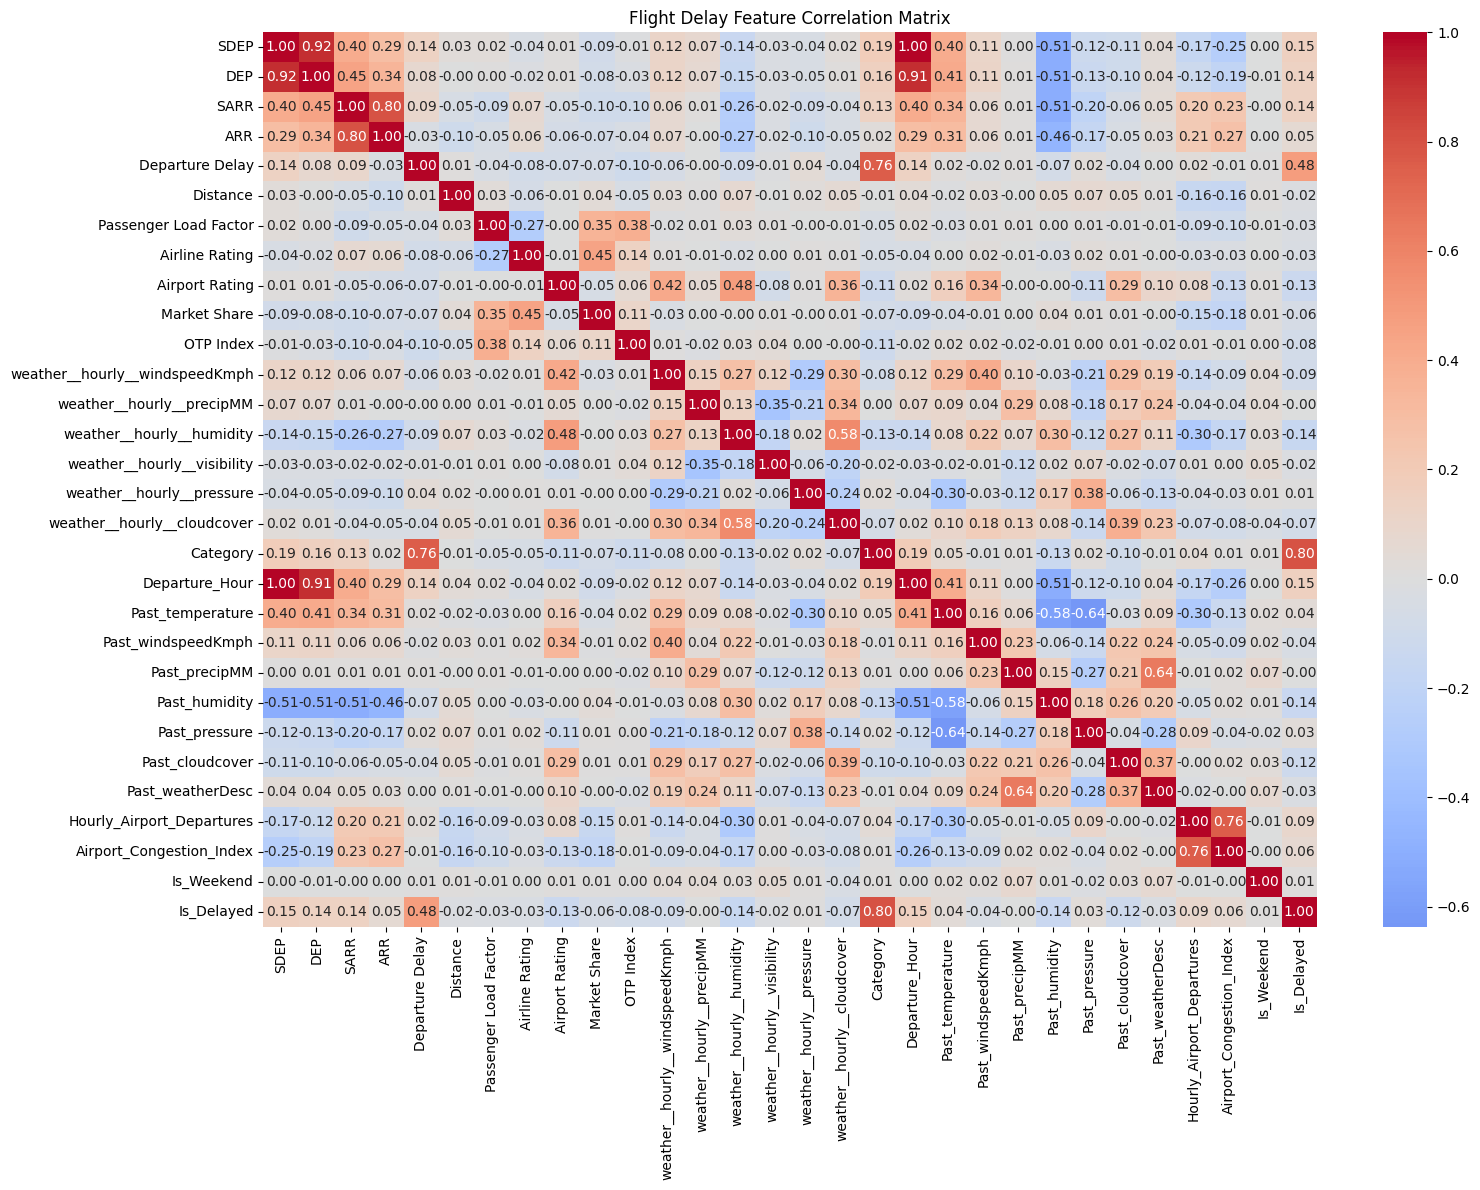

In [3]:
# Calculate correlations for numeric columns
corr_matrix = data.select_dtypes(include="number").corr()

# Plot heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Flight Delay Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [5]:
significant_features = [
    "weather__hourly__windspeedKmph",
    "weather__hourly__humidity",
    "weather__hourly__cloudcover",
    "Past_temperature",
    "Past_humidity",
    "Past_pressure",
    "Past_cloudcover",
    "Market Share",
    "Passenger Load Factor",
    "OTP Index",
    "Hourly_Airport_Departures",
    "weather__hourly__weatherDesc__value_Partly cloudy",
    "weather__hourly__weatherDesc__value_Sunny"
]

In [9]:

data = pd.read_csv("flight_data_cleaned.csv")

# Create feature matrix
weather_cols = [
    c for c in data.columns
    if c.startswith(("weather__hourly__", "Past_"))
]

other_cols = [
    "Market Share",
    "Passenger Load Factor",
    "Distance",
    "OTP Index",
    "Airport_Congestion_Index",
    "Hourly_Airport_Departures"
]

X = data[weather_cols + other_cols].copy()

# Encode categorical weather features
X["Past_weatherDesc"] = X["Past_weatherDesc"].astype(str)
X = pd.get_dummies(X, drop_first=True, dtype=float)

# Same 13 features as reduced Logistic Regression
significant_features = [
    "weather__hourly__windspeedKmph",
    "weather__hourly__humidity",
    "weather__hourly__cloudcover",
    "Past_temperature",
    "Past_humidity",
    "Past_pressure",
    "Past_cloudcover",
    "Market Share",
    "Passenger Load Factor",
    "OTP Index",
    "Hourly_Airport_Departures",
    "weather__hourly__weatherDesc__value_Partly cloudy",
    "weather__hourly__weatherDesc__value_Sunny"
]

X = X[significant_features].copy()

# Original delay > 0 classification
y = (data["Departure Delay"] > 0).astype(int)

print("X shape:", X.shape)
print("Class distribution:")
print(y.value_counts(normalize=True) * 100)

X shape: (10642, 13)
Class distribution:
Departure Delay
0    51.409509
1    48.590491
Name: proportion, dtype: float64


In [12]:
# 5-fold cross-validation
kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# KNN with 5 neighbors
knn = make_pipeline(
    SimpleImputer(strategy="median", keep_empty_features=True),
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=21)
)

# Cross-validated predictions
y_pred = cross_val_predict(knn, X, y, cv=kfold)

# Calculate metrics
tn, fp, fn, tp = confusion_matrix(y, y_pred).ravel()

print(f"Overall Accuracy: {accuracy_score(y, y_pred):.2%}")
print(f"F1 Score: {f1_score(y, y_pred):.4f}")
print(f"False Positive Rate: {fp / (fp + tn):.2%}")
print(f"False Negative Rate: {fn / (fn + tp):.2%}")
print(f"Recall: {tp / (tp + fn):.2%}")
print("\nConfusion Matrix:")
print(confusion_matrix(y, y_pred))

Overall Accuracy: 64.87%
F1 Score: 0.6327
False Positive Rate: 32.68%
False Negative Rate: 37.73%
Recall: 62.27%

Confusion Matrix:
[[3683 1788]
 [1951 3220]]


In [11]:
for k in [3, 5, 7, 9, 11, 15, 21, 31]:
    model = make_pipeline(
        SimpleImputer(strategy="median", keep_empty_features=True),
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    scores = cross_val_score(
        model, X, y, cv=kfold, scoring="accuracy"
    )

    print(f"k={k}: {scores.mean():.2%}")

k=3: 62.76%
k=5: 63.47%
k=7: 63.94%
k=9: 63.87%
k=11: 64.15%
k=15: 64.55%
k=21: 64.87%
k=31: 64.62%


In [45]:
# Target
y = data["Is_Delayed"]

# Remove original weather features
original_weather = [
    col for col in data.columns
    if col.startswith("weather__hourly__")
]

# Remove target leakage and unnecessary columns
drop_cols = original_weather + [
    "Is_Delayed",
    "Departure Delay",
    "Category",
    "Departure",
    "Arrival",
    "Arrival Delay",
    "Actual_DateTime",
    "Status",
    "Scheduled_DateTime",
    "Weather_Cutoff",
    "Used Date",
    "Scheduled Departure",
    "Scheduled Arrival"
]

X = data.drop(columns=drop_cols, errors="ignore")

# Remove remaining datetime columns
X = X.select_dtypes(exclude=["datetime", "datetimetz"])

# One-hot encode categorical features
X = pd.get_dummies(X, dtype=int)

# Ensure numeric values
X = X.apply(pd.to_numeric, errors="coerce")

print("Number of features:", X.shape[1])
print("Past weather columns:", [c for c in X.columns if c.startswith("Past_")])

Number of features: 2307
Past weather columns: ['Past_temperature', 'Past_windspeedKmph', 'Past_precipMM', 'Past_humidity', 'Past_pressure', 'Past_cloudcover', 'Past_weatherDesc']


In [46]:
import pandas as pd

data = pd.read_csv("flight_data_cleaned.csv")

weather_cols = [
    c for c in data.columns
    if c.startswith(("weather__hourly__", "Past_"))
]

other_cols = [
    "Market Share",
    "Passenger Load Factor",
    "Distance",
    "OTP Index",
    "Airport_Congestion_Index",
    "Hourly_Airport_Departures"
]

X = data[weather_cols + other_cols].copy()

X["Past_weatherDesc"] = X["Past_weatherDesc"].astype(str)
X = pd.get_dummies(X, drop_first=True, dtype=float)

# Same 13 features as reduced Logistic Regression
significant_features = [
    "weather__hourly__windspeedKmph",
    "weather__hourly__humidity",
    "weather__hourly__cloudcover",
    "Past_temperature",
    "Past_humidity",
    "Past_pressure",
    "Past_cloudcover",
    "Market Share",
    "Passenger Load Factor",
    "OTP Index",
    "Hourly_Airport_Departures",
    "weather__hourly__weatherDesc__value_Partly cloudy",
    "weather__hourly__weatherDesc__value_Sunny"
]

X = X[significant_features].copy()

# Keep your new 15-minute delay target
y = (data["Departure Delay"] > 15).astype(int)

print(X.shape)

(10642, 13)


In [47]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

knn = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=3)
)

y_pred = cross_val_predict(knn, X, y, cv=cv)

tn, fp, fn, tp = confusion_matrix(y, y_pred).ravel()

print(f"Accuracy: {accuracy_score(y, y_pred):.2%}")
print(f"F1 Score: {f1_score(y, y_pred):.4f}")
print(f"False Positive Rate: {fp / (fp + tn):.2%}")
print(f"False Negative Rate: {fn / (fn + tp):.2%}")

Accuracy: 72.30%
F1 Score: 0.4300
False Positive Rate: 15.15%
False Negative Rate: 61.46%


In [ ]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, recall_score

for k in [3, 5, 7, 9, 11, 15, 21, 31]:
    model = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    scores = cross_validate(
        model, X, y,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "f1": "f1",
            "recall": "recall"
        }
    )

    print(
        f"k={k:2d} | "
        f"Accuracy={scores['test_accuracy'].mean():.2%} | "
        f"F1={scores['test_f1'].mean():.4f} | "
        f"Recall={scores['test_recall'].mean():.2%}"
    )

k= 3 | Accuracy=72.30% | F1=0.4299 | Recall=38.54%
k= 5 | Accuracy=73.01% | F1=0.4046 | Recall=33.86%
k= 7 | Accuracy=73.71% | F1=0.3937 | Recall=31.54%
k= 9 | Accuracy=73.88% | F1=0.3770 | Recall=29.19%


In [ ]:
print(y.value_counts(normalize=True) * 100)

print("Actual accuracy:", accuracy_score(y, y_pred))
print("Confusion matrix:")
print(confusion_matrix(y, y_pred))

Departure Delay
0    72.890434
1    27.109566
Name: proportion, dtype: float64
Actual accuracy: 0.722984401428303
Confusion matrix:
[[6582 1175]
 [1773 1112]]
